In [8]:
import tensorflow as tf
from tensorflow.keras import models, layers
import matplotlib.pyplot as plt
from IPython.display import HTML
%pip install scipy

Note: you may need to restart the kernel to use updated packages.


In [9]:
IMAGE_SIZE = 256
CHANNELS = 3

In [3]:
import os

print("Current working directory:", os.getcwd())
print("Files and folders:", os.listdir())

Current working directory: C:\potato-disease\training
Files and folders: ['.ipynb_checkpoints', 'AugmentedImages', 'dataset', 'final.ipynb', 'my_model.keras', 'PlantVillage', 'training.ipynb']


In [4]:
import os

print("Dataset exists:", os.path.isdir("dataset"))
print("Training folder exists:", os.path.isdir("dataset/train"))

Dataset exists: True
Training folder exists: True


In [5]:
import os

DATASET_DIR = r"C:\potato-disease\training\PlantVillage"

print("Dataset exists:", os.path.isdir(DATASET_DIR))

if os.path.isdir(DATASET_DIR):
    print("\nContents of PlantVillage:")
    for item in sorted(os.listdir(DATASET_DIR)):
        full_path = os.path.join(DATASET_DIR, item)
        if os.path.isdir(full_path):
            print(f"[FOLDER] {item}")
        else:
            print(f"[FILE]   {item}")

Dataset exists: True

Contents of PlantVillage:
[FOLDER] Potato___Early_blight
[FOLDER] Potato___Late_blight
[FOLDER] Potato___healthy


In [2]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(
        rescale=1./255,
        rotation_range=10,
        horizontal_flip=True
)
train_generator = train_datagen.flow_from_directory(
        'dataset/train',
        target_size=(IMAGE_SIZE,IMAGE_SIZE),
        batch_size=32,
        class_mode="sparse",
        #save_to_dir="C:\\Code\\potato-disease-classification\\training\\AugmentedImages"
)

Found 1506 images belonging to 3 classes.


In [8]:
#MY Work
import tensorflow as tf

MODEL_PATH = r"C:\potato-disease\training\my_model.keras"

model = tf.keras.models.load_model(MODEL_PATH)

print("Model input shape:", model.input_shape)
print("Model output shape:", model.output_shape)

Model input shape: (None, 256, 256, 3)
Model output shape: (None, 3)


In [9]:
#My Work
# Verify model and training generator compatibility

print("Model input shape:", model.input_shape)
print("Generator image shape:", train_generator.image_shape)
print("Generator class indices:", train_generator.class_indices)
print("Model output classes:", model.output_shape[-1])

assert model.input_shape[1:] == (
    IMAGE_SIZE,
    IMAGE_SIZE,
    3,
), "Image size or channels do not match the model."

assert model.output_shape[-1] == train_generator.num_classes, (
    "Model output count does not match the number of dataset classes."
)

print("\nModel and generator dimensions are compatible.")


Model input shape: (None, 256, 256, 3)
Generator image shape: (256, 256, 3)
Generator class indices: {'Potato___Early_blight': 0, 'Potato___Late_blight': 1, 'Potato___healthy': 2}
Model output classes: 3

Model and generator dimensions are compatible.


In [10]:
#My Work
train_generator.class_indices

{'Potato___Early_blight': 0, 'Potato___Late_blight': 1, 'Potato___healthy': 2}

In [ ]:
#My Work
class_names = list(train_generator.class_indices.keys())
class_names

In [3]:
for image_batch, label_batch in train_generator:
    print(image_batch[0])
    break

[[[0.44103503 0.37828994 0.41750562]
  [0.46654454 0.40379944 0.44301513]
  [0.5196267  0.45688155 0.49609724]
  ...
  [0.6343965  0.5873377  0.62655336]
  [0.612082   0.5650232  0.60423887]
  [0.6021023  0.55504346 0.59425914]]

 [[0.45318866 0.39044356 0.42965925]
  [0.46703604 0.40429094 0.44350663]
  [0.54837847 0.48563337 0.52484906]
  ...
  [0.6308054  0.58374655 0.62296224]
  [0.6153537  0.5682949  0.60751057]
  [0.60812604 0.5610672  0.6002829 ]]

 [[0.45925924 0.39651415 0.43572983]
  [0.5033903  0.44064522 0.4798609 ]
  [0.54640496 0.4836598  0.52287555]
  ...
  [0.62823576 0.58117694 0.6203926 ]
  [0.6216253  0.5745665  0.61378217]
  [0.6180713  0.57101244 0.6102282 ]]

 ...

 [[0.4394985  0.38851812 0.4551848 ]
  [0.47300458 0.42202416 0.48869085]
  [0.52188426 0.47090387 0.53757054]
  ...
  [0.5425168  0.5307521  0.6052619 ]
  [0.55387145 0.54210675 0.61661655]
  [0.54486734 0.53310263 0.60761243]]

 [[0.4480296  0.39704922 0.46371588]
  [0.4667443  0.4157639  0.48243058]


In [5]:
validation_datagen = ImageDataGenerator(
        rescale=1./255,
        rotation_range=10,
        horizontal_flip=True)
validation_generator = validation_datagen.flow_from_directory(
        'dataset/val',
        target_size=(IMAGE_SIZE,IMAGE_SIZE),
        batch_size=32,
        class_mode="sparse"
)

Found 215 images belonging to 3 classes.


In [4]:
test_datagen = ImageDataGenerator(
        rescale=1./255,
        rotation_range=10,
        horizontal_flip=True)

test_generator = test_datagen.flow_from_directory(
        'dataset/test',
        target_size=(IMAGE_SIZE,IMAGE_SIZE),
        batch_size=32,
        class_mode="sparse"
)

Found 431 images belonging to 3 classes.


In [6]:
for image_batch, label_batch in test_generator:
    print(image_batch[0])
    break

[[[0.6666667  0.60784316 0.63529414]
  [0.6690238  0.6102003  0.63765126]
  [0.69473535 0.6359118  0.6633628 ]
  ...
  [0.678936   0.6161909  0.6554066 ]
  [0.68173844 0.61899334 0.658209  ]
  [0.6834469  0.6207018  0.6599175 ]]

 [[0.66963696 0.61081344 0.6382644 ]
  [0.6666667  0.60784316 0.63529414]
  [0.69301    0.63418645 0.6616374 ]
  ...
  [0.6923255  0.6295804  0.66879606]
  [0.6937267  0.6309816  0.6701973 ]
  [0.6954646  0.6327195  0.6719352 ]]

 [[0.6831819  0.62435836 0.65180933]
  [0.6666667  0.60784316 0.63529414]
  [0.68974054 0.63091695 0.65836793]
  ...
  [0.7073027  0.6445576  0.6837733 ]
  [0.709171   0.6464259  0.6856416 ]
  [0.7101128  0.6473677  0.6865834 ]]

 ...

 [[0.13333334 0.11857352 0.17708823]
  [0.13333334 0.11733057 0.17599586]
  [0.13333334 0.11639643 0.17459466]
  ...
  [0.59852636 0.5397028  0.5671538 ]
  [0.6905333  0.63170975 0.65916073]
  [0.65350366 0.59468013 0.6221311 ]]

 [[0.13333334 0.11047739 0.16571608]
  [0.132812   0.10954326 0.16444522]


In [10]:
input_shape = (IMAGE_SIZE, IMAGE_SIZE, CHANNELS)
n_classes = 3

model = models.Sequential([
    layers.InputLayer(input_shape=input_shape),
    layers.Conv2D(32, kernel_size = (3,3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64,  kernel_size = (3,3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64,  kernel_size = (3,3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(n_classes, activation='softmax'),
])

C:\Users\sim\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


In [11]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 254, 254, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 127, 127, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 125, 125, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 62, 62, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 60, 60, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 30, 30, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 28, 28, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 14, 14, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 12, 12, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 6, 6, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 4, 4, 64)            │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 2, 2, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │          16,448 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 3)                   │             195 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 183,747 (717.76 KB)

 Trainable params: 183,747 (717.76 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

In [14]:
history = model.fit(
    train_generator,
    steps_per_epoch=47,
    batch_size=32,
    validation_data=validation_generator,
    validation_steps=6,
    verbose=1,
    epochs=20,
)

Epoch 1/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 120s 3s/step - accuracy: 0.9254 - loss: 0.1955 - val_accuracy: 0.8698 - val_loss: 0.2580
Epoch 2/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 10s 184ms/step - accuracy: 0.8750 - loss: 0.3511 - val_accuracy: 0.8958 - val_loss: 0.2318
Epoch 3/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 122s 3s/step - accuracy: 0.9328 - loss: 0.1717 - val_accuracy: 0.8281 - val_loss: 0.4609
Epoch 4/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 9s 149ms/step - accuracy: 0.8438 - loss: 0.3750 - val_accuracy: 0.8646 - val_loss: 0.3506
Epoch 5/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 116s 2s/step - accuracy: 0.9403 - loss: 0.1580 - val_accuracy: 0.9427 - val_loss: 0.1727
Epoch 6/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 9s 164ms/step - accuracy: 0.9688 - loss: 0.0899 - val_accuracy: 0.9167 - val_loss: 0.1841
Epoch 7/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 142s 3s/step - accuracy: 0.9437 - loss: 0.1347 - val_accuracy: 0.9271 - val_loss: 0.2045
Epoch 8/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 11s 191ms/step - accuracy: 0.9062 - loss: 0.1274 - val_accuracy: 0.93

In [15]:
history

In [16]:
history.params

{'verbose': 1, 'epochs': 20, 'steps': 47}

In [17]:
history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

In [18]:
type(history.history['loss'])

list

In [19]:
len(history.history['loss'])

20

In [20]:
history.history['loss'][:5] # show loss for first 5 epochs

[0.19550473988056183,
 0.3511124849319458,
 0.171731635928154,
 0.37498077750205994,
 0.15799012780189514]

In [21]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

In [22]:
val_acc

[0.8697916865348816,
 0.8958333134651184,
 0.828125,
 0.8645833134651184,
 0.9427083134651184,
 0.9166666865348816,
 0.9270833134651184,
 0.9375,
 0.9427083134651184,
 0.9322916865348816,
 0.9427083134651184,
 0.921875,
 0.8958333134651184,
 0.9166666865348816,
 0.953125,
 0.9583333134651184,
 0.7447916865348816,
 0.8125,
 0.9270833134651184,
 0.8854166865348816]

In [23]:
acc

[0.9253731369972229,
 0.875,
 0.9328358173370361,
 0.84375,
 0.9402984976768494,
 0.96875,
 0.9436906576156616,
 0.90625,
 0.9606512784957886,
 1.0,
 0.9620081186294556,
 0.96875,
 0.9674355387687683,
 0.9375,
 0.9592944383621216,
 0.96875,
 0.896879255771637,
 0.71875,
 0.8331071734428406,
 0.9375]

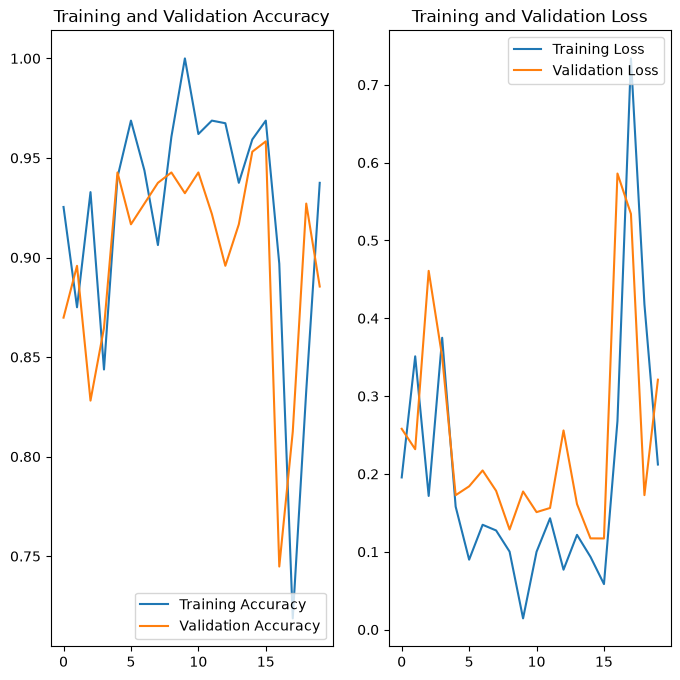

In [24]:
EPOCHS = 20

plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(range(EPOCHS), acc, label='Training Accuracy')
plt.plot(range(EPOCHS), val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(range(EPOCHS), loss, label='Training Loss')
plt.plot(range(EPOCHS), val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

In [26]:
scores = model.evaluate(test_generator)

14/14 ━━━━━━━━━━━━━━━━━━━━ 14s 958ms/step - accuracy: 0.9211 - loss: 0.2369


first image to predict


NameError: name 'class_names' is not defined

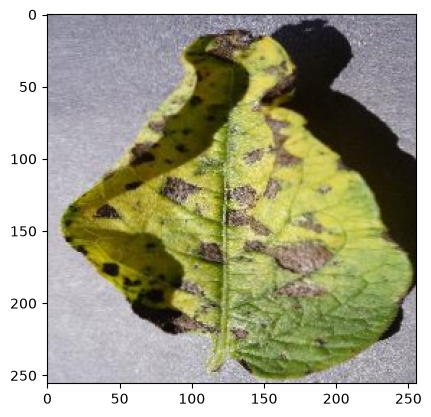

In [27]:
import numpy as np


for image_batch, label_batch in test_generator:
    first_image = image_batch[0]
    first_label = int(label_batch[0])
    
    print("first image to predict")
    plt.imshow(first_image)
    print("actual label:",class_names[first_label])
    
    batch_prediction = model.predict(images_batch)
    print("predicted label:",class_names[np.argmax(batch_prediction[0])])
    
    break


In [28]:
def predict(model, img):
    img_array = tf.keras.preprocessing.image.img_to_array(images[i])
    img_array = tf.expand_dims(img_array, 0)

    predictions = model.predict(img_array)

    predicted_class = class_names[np.argmax(predictions[0])]
    confidence = round(100 * (np.max(predictions[0])), 2)
    return predicted_class, confidence

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step


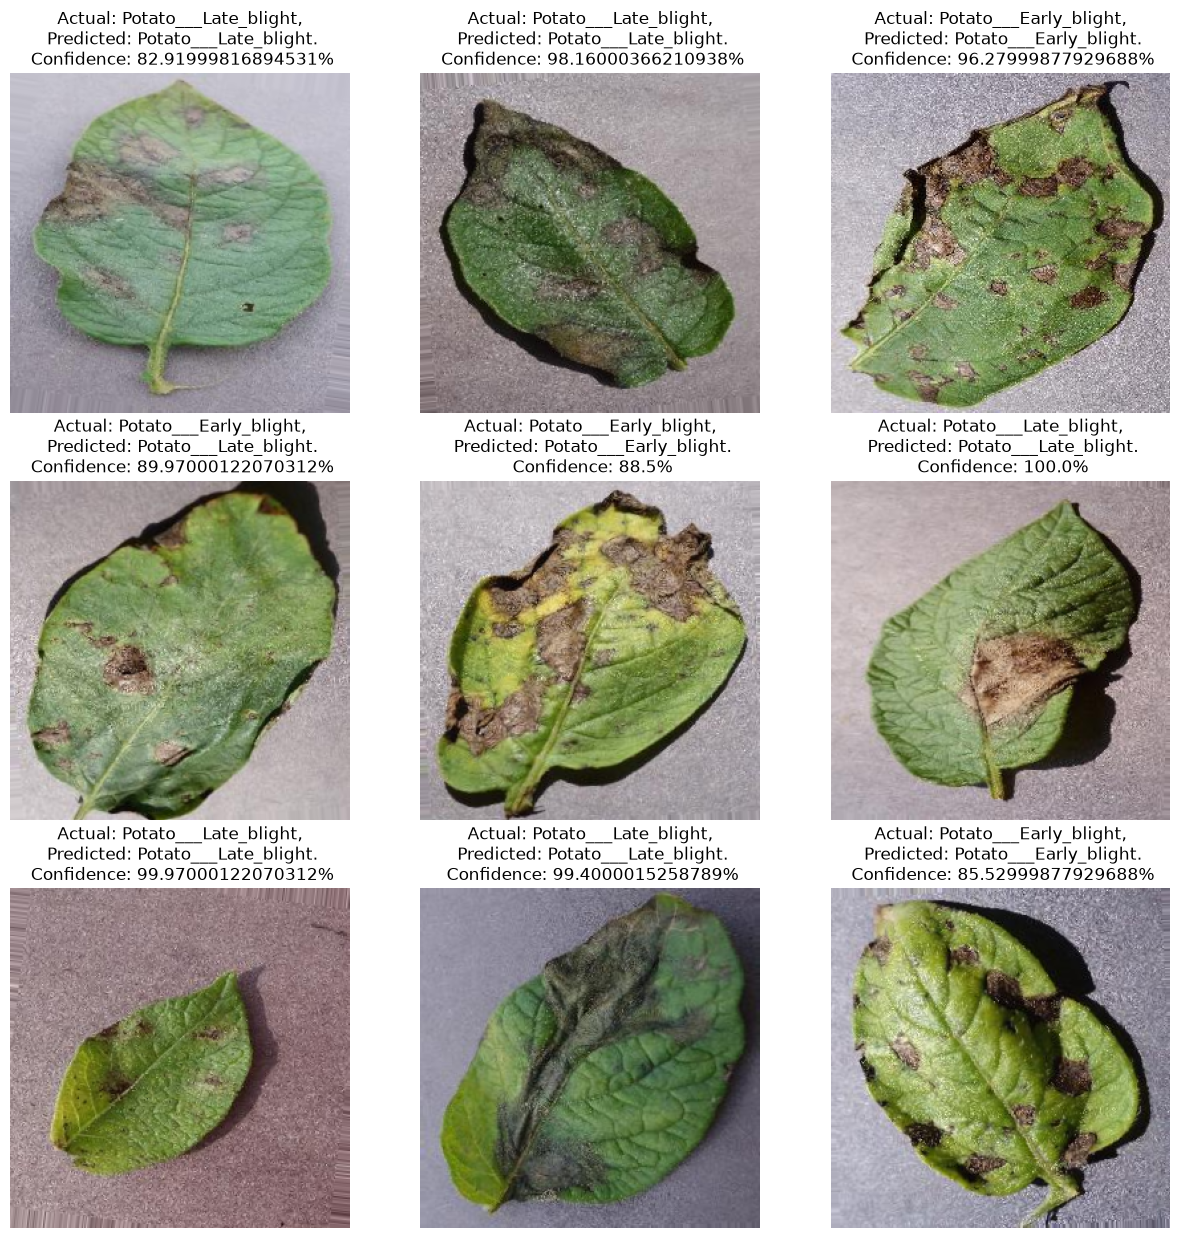

In [32]:
plt.figure(figsize=(15, 15))
class_names = list(test_generator.class_indices.keys())
for images, labels in test_generator:
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i])
        
        predicted_class, confidence = predict(model, images[i])
        actual_class = class_names[int(labels[i])] 
        
        plt.title(f"Actual: {actual_class},\n Predicted: {predicted_class}.\n Confidence: {confidence}%")
        
        plt.axis("off")
    break

In [30]:
model.save("../potatoes.keras")

In [31]:
import os

print("Model saved:", os.path.exists("../potatoes.keras"))
print("Full path:", os.path.abspath("../potatoes.keras"))

Model saved: True
Full path: C:\potato-disease\potatoes.keras
